# Clasificación de imágenes: perros y gatos

En este notebook se inspeccionan y preparan las imágenes, se construye un clasificador EfficientNetB0, se entrena con un conjunto de validación y se reserva el conjunto de prueba para la evaluación final. Las etiquetas se obtienen del prefijo `cat` o `dog` de cada nombre de archivo.

El enunciado menciona imágenes de 200×200, pero la arquitectura indicada requiere `input_shape=(224, 224, 3)`. Para mantener coherencia, todo el preprocesamiento y el modelo usarán 224×224 píxeles.

In [ ]:
from pathlib import Path
import os
import tempfile
from collections import Counter

os.environ.setdefault("TF_NUM_INTRAOP_THREADS", "1")
os.environ.setdefault("TF_NUM_INTEROP_THREADS", "1")

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

SEMILLA = 42
np.random.seed(SEMILLA)

RAIZ_PROYECTO = next(
    (ruta for ruta in (Path.cwd(), *Path.cwd().parents) if (ruta / "data/raw/train").is_dir()),
    None,
)
if RAIZ_PROYECTO is None:
    raise FileNotFoundError(
        "No se encontró data/raw/train. El dataset no está disponible en el repositorio "
        "y los recursos consultados no proporcionan un enlace de descarga verificable."
    )

DIRECTORIO_DATOS = RAIZ_PROYECTO / "data/raw/train"
DIRECTORIO_MODELOS = RAIZ_PROYECTO / "models"
DIRECTORIO_MODELOS.mkdir(exist_ok=True)

TAMANO_PAGINA = os.sysconf("SC_PAGE_SIZE")
memoria_total_gb = TAMANO_PAGINA * os.sysconf("SC_PHYS_PAGES") / 1024**3git 
memoria_disponible_gb = TAMANO_PAGINA * os.sysconf("SC_AVPHYS_PAGES") / 1024**3
archivos = sorted(
    ruta for ruta in DIRECTORIO_DATOS.iterdir()
    if ruta.is_file() and ruta.suffix.lower() in {".jpg", ".jpeg", ".png"}
)
conteo_clases = {
    clase: sum(ruta.name.lower().startswith(f"{clase}.") for ruta in archivos)
    for clase in ("cat", "dog")
}

print(f"RAM total: {memoria_total_gb:.2f} GB; disponible: {memoria_disponible_gb:.2f} GB")
print(f"Imágenes encontradas en {DIRECTORIO_DATOS}: {len(archivos):,}")
print(f"Distribución por nombre de archivo: {conteo_clases}")
print(f"Existe un test independiente: {(RAIZ_PROYECTO / 'data/raw/test').is_dir()}")
if not archivos or any(conteo_clases[clase] == 0 for clase in ("cat", "dog")):
    raise ValueError("El directorio debe contener imágenes con prefijos cat. y dog.")

RAM total: 7.76 GB; disponible: 0.17 GB
Imágenes encontradas en /workspaces/Hugo-VC-image-classifier-tutorial/data/raw/train: 25,000
Distribución por nombre de archivo: {'cat': 12500, 'dog': 12500}
Existe un test independiente: False


## 1. Inspección de imágenes

Se muestran ejemplos de ambas clases y se observan las dimensiones originales. Más adelante, la carga de Keras las redimensiona a 224×224; las etiquetas se derivan de los nombres `cat.*` y `dog.*`.

Gato: cat.0.jpg; tamaño original=(500, 374)
Perro: dog.0.jpg; tamaño original=(499, 375)


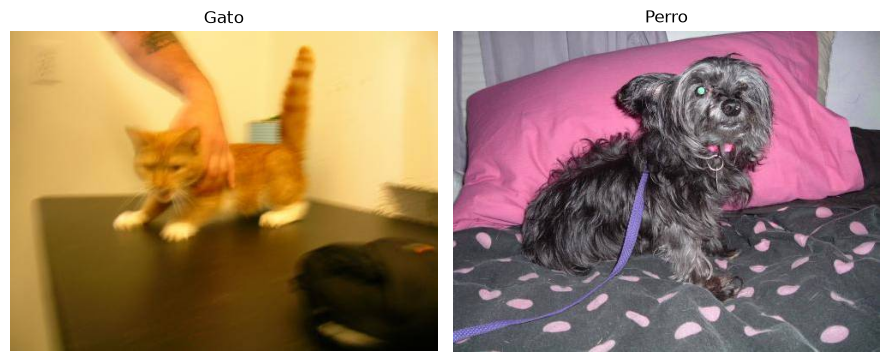

In [2]:
muestras = {}
for clase, nombre_es in (("cat", "Gato"), ("dog", "Perro")):
    ruta = next((ruta for ruta in archivos if ruta.name.lower().startswith(f"{clase}.")), None)
    if ruta is None:
        raise ValueError(f"No se encontró una imagen para la clase {clase}.")
    with Image.open(ruta) as imagen:
        muestras[clase] = imagen.convert("RGB").copy()
    print(f"{nombre_es}: {ruta.name}; tamaño original={muestras[clase].size}")

fig, ejes = plt.subplots(1, 2, figsize=(9, 4))
for eje, (clase, nombre_es) in zip(ejes, (("cat", "Gato"), ("dog", "Perro"))):
    eje.imshow(muestras[clase])
    eje.set_title(nombre_es)
    eje.axis("off")
plt.tight_layout()
plt.show()

## 2. Limpieza y partición estratificada

El repositorio contiene las imágenes etiquetadas en `data/raw/train`, pero no una carpeta de prueba independiente. Se omiten imágenes dañadas y se crean particiones estratificadas y reproducibles: 70 % para entrenamiento, 15 % para validación y 15 % para prueba. Los archivos se enlazan simbólicamente en una carpeta temporal; el conjunto de prueba no participa en el ajuste ni en la selección del modelo.

In [3]:
from sklearn.model_selection import train_test_split

archivos_validos = []
for ruta in archivos:
    if not (ruta.name.lower().startswith("cat.") or ruta.name.lower().startswith("dog.")):
        continue
    try:
        with Image.open(ruta) as imagen:
            imagen.verify()
        archivos_validos.append(ruta)
    except (OSError, ValueError):
        print(f"Imagen dañada omitida: {ruta.name}")

etiquetas = ["cat" if ruta.name.lower().startswith("cat.") else "dog" for ruta in archivos_validos]
if len(set(etiquetas)) != 2:
    raise ValueError("Después de limpiar, deben quedar imágenes válidas de ambas clases.")

rutas_entrenamiento_validacion, rutas_prueba = train_test_split(
    archivos_validos,
    test_size=0.15,
    random_state=SEMILLA,
    stratify=etiquetas,
)
etiquetas_entrenamiento_validacion = [
    "cat" if ruta.name.lower().startswith("cat.") else "dog"
    for ruta in rutas_entrenamiento_validacion
]
rutas_entrenamiento, rutas_validacion = train_test_split(
    rutas_entrenamiento_validacion,
    test_size=0.15 / 0.85,
    random_state=SEMILLA,
    stratify=etiquetas_entrenamiento_validacion,
)

particiones = {
    "train": rutas_entrenamiento,
    "validation": rutas_validacion,
    "test": rutas_prueba,
}
_directorio_temporal = tempfile.TemporaryDirectory(prefix="clasificacion_gatos_perros_")
DIRECTORIO_PARTICIONES = Path(_directorio_temporal.name)

for nombre_particion, rutas in particiones.items():
    for clase in ("cat", "dog"):
        (DIRECTORIO_PARTICIONES / nombre_particion / clase).mkdir(parents=True, exist_ok=True)
    for ruta in rutas:
        clase = "cat" if ruta.name.lower().startswith("cat.") else "dog"
        (DIRECTORIO_PARTICIONES / nombre_particion / clase / ruta.name).symlink_to(ruta.resolve())

for nombre_particion, rutas in particiones.items():
    distribucion = Counter(
        "cat" if ruta.name.lower().startswith("cat.") else "dog"
        for ruta in rutas
    )
    print(f"{nombre_particion}: {len(rutas):,} imágenes; distribución={dict(distribucion)}")

assert not (set(rutas_entrenamiento) & set(rutas_validacion))
assert not (set(rutas_entrenamiento) & set(rutas_prueba))
assert not (set(rutas_validacion) & set(rutas_prueba))

train: 17,499 imágenes; distribución={'dog': 8750, 'cat': 8749}
validation: 3,751 imágenes; distribución={'cat': 1876, 'dog': 1875}
test: 3,750 imágenes; distribución={'cat': 1875, 'dog': 1875}


## 3. Carga de imágenes y comprobación de etiquetas

La RAM disponible determina la estrategia. Con más de 12 GB disponibles se cargan las imágenes en arrays `uint8` mediante las utilidades de procesamiento de imágenes de Keras; con menos, se usa `ImageDataGenerator.flow_from_directory` por lotes, con directorios separados por partición y clase. El tamaño 224×224 se aplica en ambas rutas. EfficientNetB0 incorpora el preprocesamiento de entrada y recibe valores de píxel entre 0 y 255.

In [4]:
TAMANO_IMAGEN = (224, 224)
TAMANO_LOTE = 2
CLASES = ("cat", "dog")

if memoria_disponible_gb > 12:
    from tensorflow.keras.utils import img_to_array, load_img

    nombres_clases = list(CLASES)
    indices_clases = {clase: indice for indice, clase in enumerate(nombres_clases)}

    def cargar_particion_en_memoria(rutas):
        imagenes = np.empty(
            (len(rutas), *TAMANO_IMAGEN, 3),
            dtype=np.uint8,
        )
        etiquetas_particion = np.empty(len(rutas), dtype=np.int64)
        for indice, ruta in enumerate(rutas):
            imagen = load_img(ruta, target_size=TAMANO_IMAGEN, color_mode="rgb")
            imagenes[indice] = img_to_array(imagen, dtype="uint8")
            clase = "cat" if ruta.name.lower().startswith("cat.") else "dog"
            etiquetas_particion[indice] = indices_clases[clase]
        return imagenes, np.eye(len(nombres_clases), dtype=np.float32)[etiquetas_particion]

    X_train, y_train = cargar_particion_en_memoria(rutas_entrenamiento)
    X_validacion, y_validacion = cargar_particion_en_memoria(rutas_validacion)
    X_test, y_test = cargar_particion_en_memoria(rutas_prueba)
    datos_entrenamiento = (X_train, y_train)
    datos_validacion = (X_validacion, y_validacion)
    datos_prueba = (X_test, y_test)
    etiquetas_reales_prueba = np.argmax(y_test, axis=1)
    forma_lote = (min(TAMANO_LOTE, len(X_train)), *TAMANO_IMAGEN, 3)
    forma_etiquetas = (min(TAMANO_LOTE, len(y_train)), len(nombres_clases))
    print("Estrategia: imágenes cargadas en memoria con Keras (uint8).")
else:
    from tensorflow.keras.preprocessing.image import ImageDataGenerator

    generador_entrenamiento = ImageDataGenerator(
        rotation_range=12,
        width_shift_range=0.1,
        height_shift_range=0.1,
        horizontal_flip=True,
    )
    generador_evaluacion = ImageDataGenerator()

    train_generator = generador_entrenamiento.flow_from_directory(
        str(DIRECTORIO_PARTICIONES / "train"),
        target_size=TAMANO_IMAGEN,
        batch_size=TAMANO_LOTE,
        class_mode="categorical",
        classes=list(CLASES),
        shuffle=True,
        seed=SEMILLA,
    )
    validation_generator = generador_evaluacion.flow_from_directory(
        str(DIRECTORIO_PARTICIONES / "validation"),
        target_size=TAMANO_IMAGEN,
        batch_size=TAMANO_LOTE,
        class_mode="categorical",
        classes=list(CLASES),
        shuffle=False,
    )
    test_generator = generador_evaluacion.flow_from_directory(
        str(DIRECTORIO_PARTICIONES / "test"),
        target_size=TAMANO_IMAGEN,
        batch_size=TAMANO_LOTE,
        class_mode="categorical",
        classes=list(CLASES),
        shuffle=False,
    )
    nombres_clases = [
        clase for clase, indice in sorted(train_generator.class_indices.items(), key=lambda par: par[1])
    ]
    datos_entrenamiento = train_generator
    datos_validacion = validation_generator
    datos_prueba = test_generator
    etiquetas_reales_prueba = test_generator.classes
    lote_imagenes, lote_etiquetas = train_generator[0]
    forma_lote, forma_etiquetas = lote_imagenes.shape, lote_etiquetas.shape
    print("Estrategia: ImageDataGenerator.flow_from_directory por lotes.")

print("Índices de clase:", {clase: indice for indice, clase in enumerate(nombres_clases)})
print("Formas de imágenes y etiquetas de un lote:", forma_lote, forma_etiquetas)
print(
    "Tamaños (entrenamiento/validación/prueba):",
    len(rutas_entrenamiento), len(rutas_validacion), len(rutas_prueba),
)
print("Distribución de prueba:", dict(Counter(etiquetas_reales_prueba)))

I0000 00:00:1793455741.938953     891 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793455742.115972     891 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793455762.679958     891 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793455772.830429     891 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.

Found 17499 images belonging to 2 classes.
Found 3751 images belonging to 2 classes.
Found 3750 images belonging to 2 classes.
Estrategia: ImageDataGenerator.flow_from_directory por lotes.
Índices de clase: {'cat': 0, 'dog': 1}
Formas de imágenes y etiquetas de un lote: (2, 224, 224, 3) (2, 2)
Tamaños (entrenamiento/validación/prueba): 17499 3751 3750
Distribución de prueba: {np.int32(0): 1875, np.int32(1): 1875}


## 4. Modelo y entrenamiento

Se implementa la arquitectura solicitada: `EfficientNetB0(include_top=False, weights=None)`, `GlobalAveragePooling2D`, una capa densa de 128 unidades con ReLU y una salida softmax de dos clases. Se utiliza `categorical_crossentropy`, compatible con etiquetas one-hot. Si existe un checkpoint, se continúa desde él; `ModelCheckpoint` conserva el mejor resultado de la ejecución según `val_loss` y `EarlyStopping` detiene el ajuste si la validación deja de mejorar. Por el tiempo y los recursos disponibles, la continuación se limitó a una época adicional. EfficientNetB0 se inicializa sin pesos preentrenados, tal como pide el ejercicio, así que los resultados deben interpretarse teniendo en cuenta este entrenamiento limitado.

In [5]:
import tensorflow as tf
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.models import Sequential

tf.keras.utils.set_random_seed(SEMILLA)

RUTA_CHECKPOINT_BASE = DIRECTORIO_MODELOS / "cat_dog_efficientnetb0.keras"
checkpoints_previos = sorted(DIRECTORIO_MODELOS.glob("cat_dog_efficientnetb0_iter_*.keras"))
RUTA_CHECKPOINT_ENTRADA = checkpoints_previos[-1] if checkpoints_previos else RUTA_CHECKPOINT_BASE

if RUTA_CHECKPOINT_ENTRADA.exists():
    modelo = tf.keras.models.load_model(str(RUTA_CHECKPOINT_ENTRADA))
    print(f"Checkpoint cargado: {RUTA_CHECKPOINT_ENTRADA}")
    print(f"Iteraciones restauradas: {int(modelo.optimizer.iterations.numpy())}")
else:
    modelo = Sequential(
        [
            EfficientNetB0(
                include_top=False,
                weights=None,
                input_shape=(224, 224, 3),
            ),
            GlobalAveragePooling2D(),
            Dense(units=128, activation="relu"),
            Dense(units=2, activation="softmax"),
        ],
        name="clasificador_gatos_perros",
    )
    modelo.compile(
        optimizer="adam",
        loss="categorical_crossentropy",
        metrics=["accuracy"],
    )
    print("No hay checkpoint; se inicializa un modelo nuevo.")

modelo.summary()

E0000 00:00:1793455812.318548     891 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Checkpoint cargado: /workspaces/Hugo-VC-image-classifier-tutorial/models/cat_dog_efficientnetb0_iter_00113750.keras
Iteraciones restauradas: 122500


Model: "clasificador_gatos_perros"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,557,347 (47.90 MB)

 Trainable params: 4,171,774 (15.91 MB)

 Non-trainable params: 42,023 (164.16 KB)

 Optimizer params: 8,343,550 (31.83 MB)

Epoch 6/6


I0000 00:00:1793449371.527427   29657 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.


8750/8750 ━━━━━━━━━━━━━━━━━━━━ 0s 360ms/step - accuracy: 0.4981 - loss: 0.6934
Epoch 6: val_loss improved from None to 0.69315, saving model to /workspaces/Hugo-VC-image-classifier-tutorial/models/cat_dog_efficientnetb0_iter_00113750.keras

Epoch 6: finished saving model to /workspaces/Hugo-VC-image-classifier-tutorial/models/cat_dog_efficientnetb0_iter_00113750.keras
8750/8750 ━━━━━━━━━━━━━━━━━━━━ 3267s 371ms/step - accuracy: 0.4981 - loss: 0.6934 - val_accuracy: 0.4999 - val_loss: 0.6932
Restoring model weights from the end of the best epoch: 6.


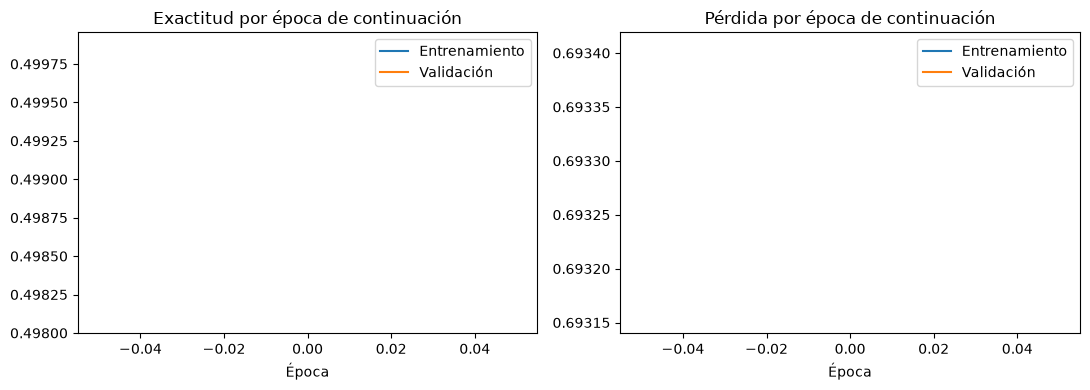

Iteraciones iniciales restauradas: 113750
Checkpoint de continuación: /workspaces/Hugo-VC-image-classifier-tutorial/models/cat_dog_efficientnetb0_iter_00113750.keras


In [6]:
from tensorflow.keras.callbacks import BackupAndRestore

ITERACIONES_INICIO = int(modelo.optimizer.iterations.numpy())
RUTA_MEJOR_MODELO = DIRECTORIO_MODELOS / (
    f"cat_dog_efficientnetb0_iter_{ITERACIONES_INICIO:08d}.keras"
)
# BackupAndRestore indica que ya se completaron cinco épocas; fijar el total
# en seis limita esta ejecución a una única época adicional.
EPOCAS_ADICIONALES = 6

respaldo_entrenamiento = BackupAndRestore(
    backup_dir=str(DIRECTORIO_MODELOS / ".respaldo_entrenamiento_gatos_perros"),
    save_freq="epoch",
)
checkpoint = ModelCheckpoint(
    filepath=str(RUTA_MEJOR_MODELO),
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=1,
)
parada_temprana = EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=5,
    restore_best_weights=True,
    verbose=1,
)

historial = modelo.fit(
    datos_entrenamiento,
    validation_data=datos_validacion,
    epochs=EPOCAS_ADICIONALES,
    callbacks=[respaldo_entrenamiento, checkpoint, parada_temprana],
    verbose=1,
)

fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
ejes[0].plot(historial.history["accuracy"], label="Entrenamiento")
ejes[0].plot(historial.history["val_accuracy"], label="Validación")
ejes[0].set_title("Exactitud por época de continuación")
ejes[0].set_xlabel("Época")
ejes[0].legend()
ejes[1].plot(historial.history["loss"], label="Entrenamiento")
ejes[1].plot(historial.history["val_loss"], label="Validación")
ejes[1].set_title("Pérdida por época de continuación")
ejes[1].set_xlabel("Época")
ejes[1].legend()
plt.tight_layout()
plt.show()

print(f"Iteraciones iniciales restauradas: {ITERACIONES_INICIO}")
print(f"Checkpoint de continuación: {RUTA_MEJOR_MODELO}")

## 5. Evaluación final en el conjunto de prueba

Se vuelve a cargar el mejor checkpoint y se evalúa el conjunto de prueba completo, que se mantuvo aparte durante el entrenamiento y la selección del modelo. Se resumen pérdida, exactitud, métricas por clase y matriz de confusión.

I0000 00:00:1793455892.760737     891 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.


1876/1876 ━━━━━━━━━━━━━━━━━━━━ 95s 49ms/step - accuracy: 0.4993 - loss: 0.6931
Validación cat_dog_efficientnetb0_iter_00078750.keras: loss=0.6931, accuracy=0.4993
1876/1876 ━━━━━━━━━━━━━━━━━━━━ 95s 49ms/step - accuracy: 0.4999 - loss: 0.6932
Validación cat_dog_efficientnetb0_iter_00113750.keras: loss=0.6932, accuracy=0.4999

Mejor checkpoint por val_loss: /workspaces/Hugo-VC-image-classifier-tutorial/models/cat_dog_efficientnetb0_iter_00078750.keras
val_loss: 0.6931
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 86s 45ms/step - accuracy: 0.4995 - loss: 0.6932

Métricas sobre todas las imágenes de prueba:
accuracy: 0.4995
loss: 0.6932
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 82s 43ms/step

Reporte por clase:
              precision    recall  f1-score   support

         cat     0.4997    0.9963    0.6656      1875
         dog     0.4167    0.0027    0.0053      1875

    accuracy                         0.4995      3750
   macro avg     0.4582    0.4995    0.3354      3750
weighted avg     0.4582    0.4995    

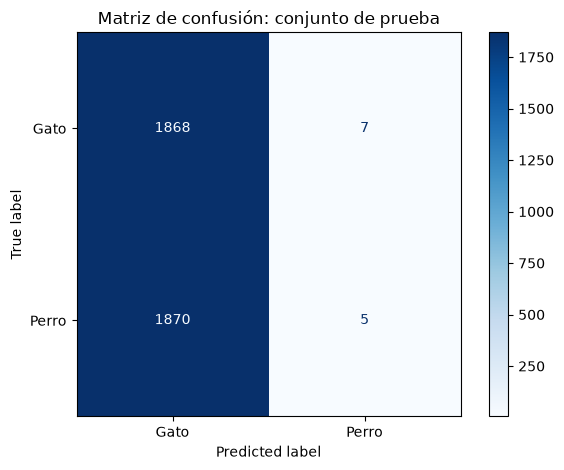

Exactitud final de prueba: 0.4995


In [6]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix

# Compara únicamente el checkpoint que se seleccionó antes de la continuación y el nuevo.
# Así se evita evaluar repetidamente todos los checkpoints antiguos en CPU.
checkpoints_candidatos = [
    DIRECTORIO_MODELOS / "cat_dog_efficientnetb0_iter_00078750.keras",
    DIRECTORIO_MODELOS / "cat_dog_efficientnetb0_iter_00113750.keras",
]
checkpoints_candidatos = [ruta for ruta in checkpoints_candidatos if ruta.exists()]
if not checkpoints_candidatos:
    raise FileNotFoundError("No se encontraron checkpoints candidatos en models/.")

resultados_validacion = []
for ruta_checkpoint in checkpoints_candidatos:
    modelo_candidato = tf.keras.models.load_model(str(ruta_checkpoint))
    validation_generator.reset()
    metricas_candidato = modelo_candidato.evaluate(
        datos_validacion,
        verbose=1,
        return_dict=True,
    )
    resultados_validacion.append((metricas_candidato["loss"], ruta_checkpoint))
    print(
        f"Validación {ruta_checkpoint.name}: "
        f"loss={metricas_candidato['loss']:.4f}, "
        f"accuracy={metricas_candidato['accuracy']:.4f}"
    )
    del modelo_candidato

mejor_val_loss, RUTA_MEJOR_MODELO = min(resultados_validacion, key=lambda resultado: resultado[0])
modelo_mejor = tf.keras.models.load_model(str(RUTA_MEJOR_MODELO))
print(f"\nMejor checkpoint por val_loss: {RUTA_MEJOR_MODELO}")
print(f"val_loss: {mejor_val_loss:.4f}")

# El conjunto de prueba se consulta solo para esta evaluación final.
test_generator.reset()
metricas_prueba = modelo_mejor.evaluate(datos_prueba, verbose=1, return_dict=True)
print("\nMétricas sobre todas las imágenes de prueba:")
for nombre, valor in metricas_prueba.items():
    print(f"{nombre}: {valor:.4f}")

test_generator.reset()
probabilidades = modelo_mejor.predict(datos_prueba, verbose=1)
predicciones = np.argmax(probabilidades, axis=1)

print("\nReporte por clase:")
print(
    classification_report(
        etiquetas_reales_prueba,
        predicciones,
        labels=np.arange(len(nombres_clases)),
        target_names=nombres_clases,
        digits=4,
        zero_division=0,
    )
)

matriz_confusion = confusion_matrix(
    etiquetas_reales_prueba,
    predicciones,
    labels=np.arange(len(nombres_clases)),
)
visualizador = ConfusionMatrixDisplay(
    confusion_matrix=matriz_confusion,
    display_labels=["Gato", "Perro"],
)
visualizador.plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusión: conjunto de prueba")
plt.tight_layout()
plt.show()

print(f"Exactitud final de prueba: {metricas_prueba['accuracy']:.4f}")

## 6. Conclusiones y observaciones para la entrega

- El conjunto disponible contiene imágenes etiquetadas en `data/raw/train`; no hay una carpeta de prueba externa. Para mantener una evaluación independiente, se separó una partición estratificada de prueba (15 %) antes de entrenar y seleccionar el checkpoint. Las particiones resultantes fueron 17.499 imágenes de entrenamiento, 3.751 de validación y 3.750 de prueba.
- Se usó resolución 224×224 para que el preprocesamiento coincida con `input_shape=(224, 224, 3)` de la arquitectura indicada. Debido a la RAM disponible, se procesaron las imágenes por lotes pequeños, sin cargar el conjunto completo en memoria.
- La selección entre los dos checkpoints recientes se hizo únicamente con la pérdida de validación. El checkpoint elegido fue `cat_dog_efficientnetb0_iter_00078750.keras` (`val_loss` ≈ 0,6932). En la evaluación final, una sola vez sobre test, obtuvo `loss` ≈ 0,6932 y `accuracy` ≈ 0,4995.
- El reporte por clase y la matriz de confusión muestran un sesgo marcado hacia la clase gato: recall de gato ≈ 0,9963 y recall de perro ≈ 0,0027. Por tanto, el modelo de esta ejecución **no es un clasificador satisfactorio**; su exactitud está prácticamente al nivel del azar en este conjunto balanceado. Se informan los resultados observados sin presentarlos como un éxito.
- El modelo se entrenó con `weights=None` y una continuación breve en CPU desde un checkpoint disponible. Esto limita lo que puede concluirse sobre el potencial de la arquitectura; para mejorar el resultado haría falta revisar el entrenamiento y disponer de más tiempo/cómputo, sin modificar la partición de prueba ni reutilizarla para ajustar el modelo.

Los checkpoints quedan guardados en `models/`. Para reproducir el flujo completo desde cero, ejecutar las celdas en orden; la celda de entrenamiento detecta checkpoints existentes y puede continuar desde ellos.